# Reefugia: validating MHW detection against marineHeatWaves
Compares reefugia's marine heatwave days with Eric Oliver's
[marineHeatWaves](https://github.com/ecjoliver/marineHeatWaves) package, the
reference implementation of Hobday et al. (2016), at a few pixels.

Both build the threshold the same way, the 90th percentile of all baseline SST
within ±5 days of each day of year, smoothed with a 31-day running mean that
wraps around the year. Both apply the same event rules, at least 5 days above
the threshold, joined across gaps of 2 days or less. The unit tests check
reefugia's event logic exactly (`tests/test_detect.py`), so the two should agree
almost exactly here.

**Setup.** marineHeatWaves isn't on PyPI and doesn't run on NumPy 2 as released.
This notebook imports a locally patched copy, `notebooks/validation/marineHeatWaves1.py`
(`np.NaN` → `np.nan`, plus one scalar indexing fix). It's GPL-3 licensed, so keep
it out of the repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copernicusmarine
from datetime import date

import marineHeatWaves1 as ref  # local patched copy, see above
from reefugia import constants, fetch, detect, visualise
from reefugia.constants import (BASELINE_START, BASELINE_END, KELVIN_TO_CELSIUS,
                                MHW_PERSISTENCE_DAYS, MHW_MAX_GAP_DAYS)

REGION = "red_sea"
YEAR   = 2023
START, END = f"{YEAR}-01-01", f"{YEAR}-12-31"
PLACE  = visualise.pretty_region(REGION)
print(f"SST product: {constants.SST_PRODUCT}")

SST product: c3s


## 1. reefugia MHW days and threshold for the region

In [2]:
sst = fetch.fetch_data(REGION, START, END)["analysed_sst"]
mhw_result = detect.load_or_compute_mhw(sst, REGION, START, END)
mhw, exceedance = mhw_result["mhw"], mhw_result["exceedance"]
mhw_days = mhw.sum(dim="time").where(sst.isel(time=0).notnull()).compute()
threshold = detect.load_or_compute_climatology(REGION)["sst_threshold"]

INFO - 2026-11-12T16:15:21Z - Selected dataset version: "202506"
INFO - 2026-11-12T16:15:21Z - Selected dataset part: "default"


## 2. Pixels to compare
The pixel with the most MHW days, plus two others. The fixed points are in the
Red Sea, so change them if you change `REGION`.

In [3]:
hot = mhw_days.where(mhw_days == mhw_days.max(), drop=True)
PIXELS = {
    "Most MHW days": (float(hot.latitude[0]), float(hot.longitude[0])),
    "Central":       (20.0, 38.5),
    "North":         (27.0, 34.5),
}
for name, (lat, lon) in PIXELS.items():
    days = mhw_days.sel(latitude=lat, longitude=lon, method="nearest")
    print(f"{name:14s} {lat:6.2f}N {lon:6.2f}E  reefugia MHW days: {int(days)}")

Most MHW days   23.98N  35.77E  reefugia MHW days: 276
Central         20.00N  38.50E  reefugia MHW days: 139
North           27.00N  34.50E  reefugia MHW days: 55


## 3. Run marineHeatWaves on each pixel's full record
marineHeatWaves builds its own climatology from the time series, so each pixel
needs the full record from the start of the baseline to the end of the analysis
year. A single-pixel request is quick.

In [4]:
def pixel_series(lat, lon):
    ds = copernicusmarine.open_dataset(
        dataset_id=fetch.dataset_id(),  # same SST product as reefugia
        minimum_longitude=lon, maximum_longitude=lon,
        minimum_latitude=lat, maximum_latitude=lat,
        start_datetime=BASELINE_START, end_datetime=END,
        variables=["analysed_sst"],
        coordinates_selection_method="nearest",
    )
    return ds["analysed_sst"].squeeze().compute() + KELVIN_TO_CELSIUS


def ref_flags(events, dates):
    t = np.array([d.toordinal() for d in dates.date])
    flags = np.zeros(len(t), dtype=bool)
    for s, e in zip(events["time_start"], events["time_end"]):
        flags |= (t >= s) & (t <= e)
    return flags


rows, series = [], {}
for name, (lat, lon) in PIXELS.items():
    temp = pixel_series(lat, lon)
    t = np.array([d.toordinal() for d in pd.DatetimeIndex(temp.time.values).date])
    events, clim = ref.detect(
        t, temp.values,
        climatologyPeriod=[int(BASELINE_START[:4]), int(BASELINE_END[:4])],
        minDuration=MHW_PERSISTENCE_DAYS, maxGap=MHW_MAX_GAP_DAYS,
    )

    in_year = pd.DatetimeIndex(temp.time.values).year == YEAR
    dates = pd.DatetimeIndex(temp.time.values[in_year])
    ours = mhw.sel(latitude=lat, longitude=lon, method="nearest").sel(time=dates.values).values
    theirs = ref_flags(events, dates)
    ours_thresh = (threshold.sel(latitude=lat, longitude=lon, method="nearest")
                            .sel(dayofyear=detect.day_of_year(dates)).values + KELVIN_TO_CELSIUS)
    ref_thresh = clim["thresh"][in_year]

    rows.append({
        "pixel": name,
        "reefugia days": int(ours.sum()),
        "marineHeatWaves days": int(theirs.sum()),
        "days agreeing (%)": 100 * (ours == theirs).mean(),
        "overlap (both / either, %)": 100 * (ours & theirs).sum() / max((ours | theirs).sum(), 1),
        "threshold diff, mean (°C)": float(np.mean(ours_thresh - ref_thresh)),
        "threshold diff, max abs (°C)": float(np.max(np.abs(ours_thresh - ref_thresh))),
    })
    series[name] = dict(dates=dates, sst=temp.values[in_year], ours=ours, theirs=theirs,
                        ours_thresh=ours_thresh, ref_thresh=ref_thresh,
                        ref_lat=float(temp.latitude), ref_lon=float(temp.longitude))

pd.DataFrame(rows).set_index("pixel").round(2)

INFO - 2026-11-12T16:15:28Z - Selected dataset version: "202506"
INFO - 2026-11-12T16:15:28Z - Selected dataset part: "default"
INFO - 2026-11-12T16:15:56Z - Selected dataset version: "202506"
INFO - 2026-11-12T16:15:56Z - Selected dataset part: "default"
INFO - 2026-11-12T16:16:11Z - Selected dataset version: "202506"
INFO - 2026-11-12T16:16:11Z - Selected dataset part: "default"


,reefugia days,marineHeatWaves days,days agreeing (%),"overlap (both / either, %)","threshold diff, mean (°C)","threshold diff, max abs (°C)"
pixel,,,,,,
Most MHW days,276,270,98.36,97.83,0.0,0.0
Central,139,139,100.00,100.00,-0.0,0.0
North,55,55,100.00,100.00,-0.0,0.0


## 4. Time series
SST with both thresholds. The strips along the top mark MHW days, reefugia
(orange, upper) and marineHeatWaves (blue, lower).

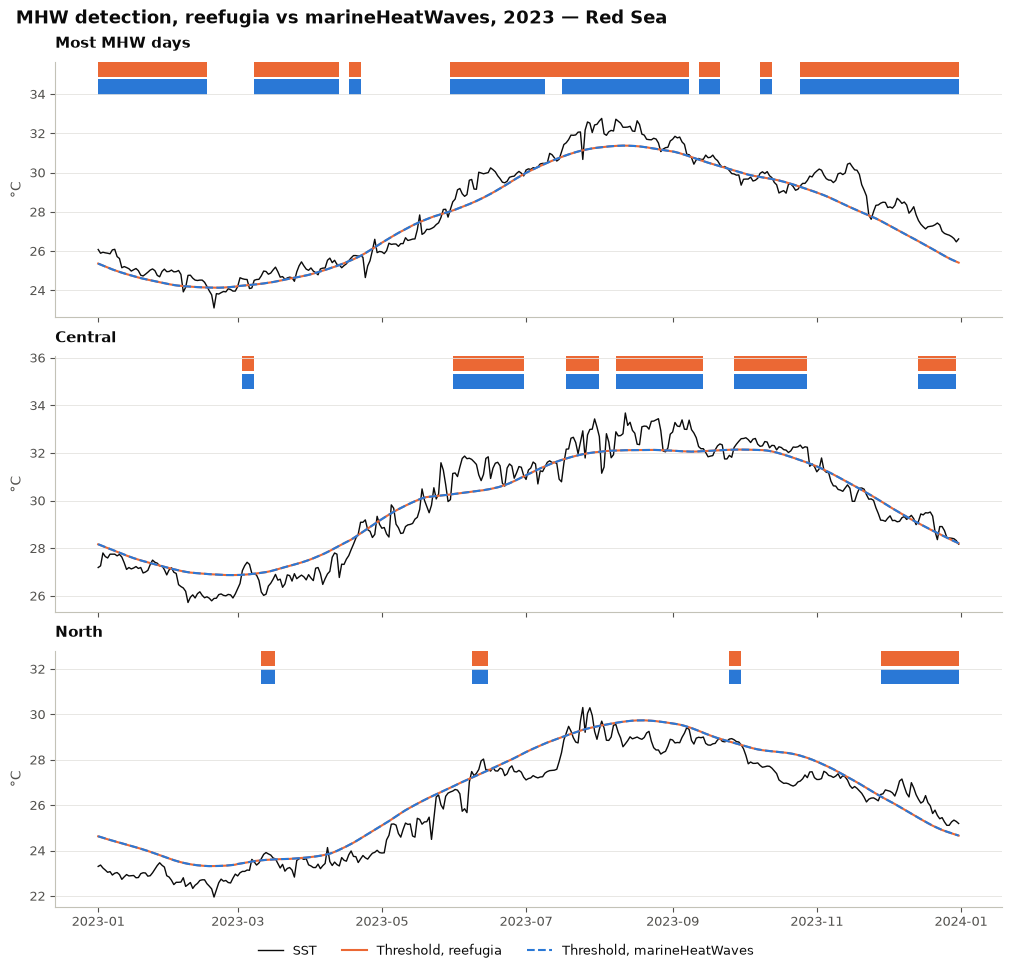

In [5]:
with plt.rc_context(visualise._STYLE):
    fig, axes = plt.subplots(len(series), 1, figsize=(10, 3.2 * len(series)),
                             layout="constrained", sharex=True)
    for ax, (name, s) in zip(np.atleast_1d(axes), series.items()):
        ax.plot(s["dates"], s["sst"], color=visualise.INK, linewidth=1, label="SST")
        ax.plot(s["dates"], s["ours_thresh"], color=visualise.ORANGE, linewidth=1.5,
                label="Threshold, reefugia")
        ax.plot(s["dates"], s["ref_thresh"], color=visualise.BLUE, linewidth=1.5,
                linestyle="--", label="Threshold, marineHeatWaves")
        strip = ax.get_xaxis_transform()
        ax.fill_between(s["dates"], 0.94, 1.0, where=s["ours"], transform=strip,
                        color=visualise.ORANGE, linewidth=0, step="mid")
        ax.fill_between(s["dates"], 0.87, 0.93, where=s["theirs"], transform=strip,
                        color=visualise.BLUE, linewidth=0, step="mid")
        # headroom so the event strips sit above the data
        lo, hi = np.nanmin(s["sst"]), np.nanmax(s["sst"])
        ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.3 * (hi - lo))
        ax.set_ylabel("°C")
        ax.yaxis.grid(True)
        ax.set_title(name, fontsize=11)
    fig.legend(*np.atleast_1d(axes)[0].get_legend_handles_labels(),
               loc="outside lower center", ncols=3)
    fig.suptitle(f"MHW detection, reefugia vs marineHeatWaves, {YEAR} — {PLACE}",
                 x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.show()

## 5. Where do the remaining day differences come from?
With identical thresholds and event rules, any difference has to come from the
SST values. reefugia reads the whole region at once, while this notebook reads
each pixel on its own. This compares the two reads of the same pixel, and which
days each counts as above the threshold.

In [6]:
rows = []
for name, (lat, lon) in PIXELS.items():
    s = series[name]
    region_pixel = sst.sel(latitude=lat, longitude=lon, method="nearest")
    region_sst = region_pixel.sel(time=s["dates"].values).values + KELVIN_TO_CELSIUS
    sst_diff = np.abs(region_sst - s["sst"])

    ours_above = exceedance.sel(latitude=lat, longitude=lon, method="nearest") \
                           .sel(time=s["dates"].values).values
    ref_above = s["sst"] > s["ref_thresh"]
    differs = ours_above != ref_above

    rows.append({
        "pixel": name,
        "same grid point": bool(np.isclose(float(region_pixel.latitude), s["ref_lat"])
                                and np.isclose(float(region_pixel.longitude), s["ref_lon"])),
        "days with different SST": int((sst_diff > 1e-4).sum()),
        "max SST diff (°C)": float(sst_diff.max()),
        "days above threshold, reefugia": int(ours_above.sum()),
        "days above threshold, marineHeatWaves": int(ref_above.sum()),
        "days above threshold that differ": int(differs.sum()),
        "MHW days that differ": int((s["ours"] != s["theirs"]).sum()),
    })
    if differs.any():
        print(f"{name}: days counted differently, with both SST reads and the threshold (°C)")
        print(pd.DataFrame({
            "region read": region_sst[differs], "pixel read": s["sst"][differs],
            "threshold": s["ref_thresh"][differs],
        }, index=s["dates"][differs].date).round(3).to_string(), "\n")

pd.DataFrame(rows).set_index("pixel").T

Most MHW days: days counted differently, with both SST reads and the threshold (°C)
            region read  pixel read  threshold
2023-07-10         30.5        30.5       30.5 



pixel,Most MHW days,Central,North
same grid point,True,True,True
days with different SST,0,0,0
max SST diff (°C),0.0,0.0,0.0
"days above threshold, reefugia",276,174,68
"days above threshold, marineHeatWaves",275,174,68
days above threshold that differ,1,0,0
MHW days that differ,6,0,0


If the days that differ are days where the two reads give slightly different SST,
and that SST sits within a few hundredths of a degree of the threshold, the
difference comes from the data access, not the method. One flipped day can make
or break a 5-day run, which is why a handful of flipped days can move the MHW
total by several days.

## Notes
- Threshold differences should be close to zero. Small ones can come from float
  rounding, or from a different SST value at the same pixel if the data were
  reprocessed between downloads.
- Any remaining day differences sit where SST is within a hair of the threshold.